# Mantenimiento predictivo de equipos biomédicos en UCI
## Notebook independiente de `ml_equipos_uci`

**Objetivo:** explorar el dataset, entrenar y evaluar modelos de clasificación para falla, necesidad de mantenimiento y evento crítico, y explorar agrupaciones de equipos. Todo el flujo está implementado en este notebook: no importa módulos ni necesita instalar el proyecto `ml_equipos_uci`.

### Antes de empezar
- Coloca `dataset_predictivo_metrologia.xls` en la misma carpeta que este notebook. En Google Colab, puedes subir el archivo cuando se solicite.
- Ejecuta las celdas en orden.
- La primera celda instala las bibliotecas necesarias.
- Este análisis es académico y no debe usarse para tomar decisiones clínicas ni reemplaza inspecciones de ingeniería biomédica.
- **Transparencia:** antes de entregar, documenta la fuente, licencia y si los datos son reales o sintéticos. No se debe afirmar que son datos reales sin verificarlo.


In [1]:
%pip install -q pandas numpy matplotlib scikit-learn xlrd openpyxl


## 1. Importaciones y configuración

In [2]:
from pathlib import Path
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, RocCurveDisplay,
    PrecisionRecallDisplay, brier_score_loss, silhouette_score, precision_recall_curve
)

SEED = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", category=FutureWarning)
print("Entorno listo. Semilla:", SEED)


## 2. Cargar el archivo Excel

Si el archivo no está junto al notebook, en Google Colab se abrirá una ventana para subirlo. No se necesita el ZIP del proyecto.

In [3]:
candidatos = [
    Path("dataset_predictivo_metrologia_nivel3.xls"),
    Path("../dataset_predictivo_metrologia_nivel3.xls"),
    Path("dataset_predictivo_metrologia.xls"),
    Path("../dataset_predictivo_metrologia.xls"),
    Path("/mnt/data/dataset_predictivo_metrologia_nivel3.xls"),
    Path("/mnt/data/dataset_predictivo_metrologia.xls"),
]
RUTA_DATOS = next((p for p in candidatos if p.exists()), None)

if RUTA_DATOS is None:
    try:
        from google.colab import files
        subidos = files.upload()
        RUTA_DATOS = Path(next(iter(subidos)))
    except Exception:
        raise FileNotFoundError(
            "No encuentro el Excel. Coloca dataset_predictivo_metrologia_nivel3.xls junto al notebook "
            "o súbelo manualmente (en Colab, usa la opción de carga)."
        )

print("Archivo:", RUTA_DATOS.resolve())
libro = pd.ExcelFile(RUTA_DATOS)
print("Hojas disponibles:", libro.sheet_names)
HOJA = "Dataset_Predictivo" if "Dataset_Predictivo" in libro.sheet_names else libro.sheet_names[0]
df_original = pd.read_excel(RUTA_DATOS, sheet_name=HOJA)
print(f"Hoja usada: {HOJA} | Dimensiones: {df_original.shape[0]:,} filas × {df_original.shape[1]} columnas")
display(df_original.head())


,ID_Registro,ID_Equipo,Tipo_Equipo,Clasificacion_Riesgo_INVIMA,Nivel_Riesgo_Num,Fecha_Reporte,Edad_Equipo_Meses,Meses_Desde_Ultimo_Mtto,Horas_Uso_Acumuladas,Fallas_Acumuladas,MTBF_Promedio_Dias,Corriente_Fuga_uA,Resistencia_Tierra_Ohms,Desviacion_Calibracion_Pct,Estado_IEC62353,Estado_Equipo,Categoria_Falla,Descripcion_Evento,Gravedad_Evento,Nivel_Gravedad,Accion_Recomendada,Target_Falla,Target_Mtto_Predictivo,Fecha_Registro_Evento,Tipo_Mtto_Programado,Dias_Para_Mtto,Fecha_Mtto_Programado,Periodicidad_Calibracion_Meses,Calibracion_Realizada,Tipo_Calibracion,Fecha_Ultima_Calibracion,Fecha_Proxima_Calibracion
0,REG-00001,BJER-01,Bomba de Infusión a Jeringa,IIB,3,2024-01-01,73.7,5.1,36595,4,560.5,77.6,0.123,1.25,Conforme,Sin falla,Sin falla,Sin falla: pruebas de seguridad eléctrica y metrología conformes,2,Bajo,Continuar plan de mantenimiento preventivo,0,0,2024-01-07,Preventivo con calibración (según plan),31,2024-02-07,6,No,No aplica,2023-08-07,2024-02-07
1,REG-00002,BJER-01,Bomba de Infusión a Jeringa,IIB,3,2024-02-01,74.7,0.3,39163,4,568.1,45.3,0.067,1.36,Conforme,Sin falla,Sin falla,Equipo óptimo: mantenimiento preventivo realizado recientemente,1,Sin riesgo,Continuar plan de mantenimiento preventivo,0,0,2024-02-19,Preventivo con calibración (según plan),182,2024-08-19,6,Sí,Programada semestral,2024-02-19,2024-08-19
2,REG-00003,BJER-01,Bomba de Infusión a Jeringa,IIB,3,2024-03-01,75.7,1.2,38096,4,575.7,32.3,0.080,0.92,Conforme,Sin falla,Sin falla,Sin falla: dentro del ciclo vigente de mantenimiento preventivo,2,Bajo,Continuar plan de mantenimiento preventivo,0,0,2024-03-03,Preventivo con calibración (según plan),169,2024-08-19,6,No,No aplica,2024-02-19,2024-08-19
3,REG-00004,BJER-01,Bomba de Infusión a Jeringa,IIB,3,2024-04-01,76.7,2.2,38077,4,583.3,103.5,0.077,1.45,Conforme,Sin falla,Sin falla,Sin falla: dentro del ciclo vigente de mantenimiento preventivo,2,Bajo,Continuar plan de mantenimiento preventivo,0,0,2024-04-07,Preventivo con calibración (según plan),134,2024-08-19,6,No,No aplica,2024-02-19,2024-08-19
4,REG-00005,BJER-01,Bomba de Infusión a Jeringa,IIB,3,2024-05-01,77.7,3.2,41042,4,590.9,82.8,0.102,0.74,Conforme,Sin falla,Sin falla,Sin falla: pruebas de seguridad eléctrica y metrología conformes,2,Bajo,Continuar plan de mantenimiento preventivo,0,1,2024-05-09,Preventivo con calibración (según plan),102,2024-08-19,6,No,No aplica,2024-02-19,2024-08-19


## 3. Validación inicial y calidad de datos

In [4]:
print("Columnas:")
display(pd.DataFrame({"columna": df_original.columns, "tipo": df_original.dtypes.astype(str).values}))
print("Valores nulos por columna (primeras 30):")
display(df_original.isna().sum().sort_values(ascending=False).head(30).to_frame("nulos"))
print("Duplicados exactos:", int(df_original.duplicated().sum()))

COLUMNAS_REQUERIDAS = [
    "ID_Registro", "ID_Equipo", "Fecha_Reporte", "Tipo_Equipo",
    "Target_Falla", "Target_Mtto_Predictivo", "Gravedad_Evento",
    "Edad_Equipo_Meses", "Meses_Desde_Ultimo_Mtto", "Horas_Uso_Acumuladas",
    "Fallas_Acumuladas", "MTBF_Promedio_Dias", "Corriente_Fuga_uA",
    "Resistencia_Tierra_Ohms", "Desviacion_Calibracion_Pct"
]
faltantes = [c for c in COLUMNAS_REQUERIDAS if c not in df_original.columns]
if faltantes:
    raise ValueError(f"El archivo no contiene las columnas esperadas: {faltantes}")

df = df_original.copy()
df["Fecha_Reporte"] = pd.to_datetime(df["Fecha_Reporte"], errors="coerce")
for c in ["Target_Falla", "Target_Mtto_Predictivo", "Gravedad_Evento"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print("Fechas inválidas:", int(df["Fecha_Reporte"].isna().sum()))
print("Rango temporal:", df["Fecha_Reporte"].min(), "a", df["Fecha_Reporte"].max())
print("Equipos únicos:", df["ID_Equipo"].nunique())
display(df["Tipo_Equipo"].value_counts(dropna=False).to_frame("registros"))

,columna,tipo
0,ID_Registro,str
1,ID_Equipo,str
2,Tipo_Equipo,str
3,Clasificacion_Riesgo_INVIMA,str
4,Nivel_Riesgo_Num,int64
5,Fecha_Reporte,datetime64[us]
6,Edad_Equipo_Meses,float64
7,Meses_Desde_Ultimo_Mtto,float64
8,Horas_Uso_Acumuladas,int64
9,Fallas_Acumuladas,int64


,nulos
ID_Registro,0
ID_Equipo,0
Tipo_Equipo,0
Clasificacion_Riesgo_INVIMA,0
Nivel_Riesgo_Num,0
Fecha_Reporte,0
Edad_Equipo_Meses,0
Meses_Desde_Ultimo_Mtto,0
Horas_Uso_Acumuladas,0
Fallas_Acumuladas,0


,registros
Tipo_Equipo,
Bomba de Infusión Volumétrica,2976
Bomba de Infusión a Jeringa,1926
Ventilador Mecánico,1174
Monitor Multiparámetro,994
Máquina CRRT,136
Desfibrilador Bifásico,136
Electrocardiógrafo 12 Derivaciones,102
Ecógrafo Portátil Doppler,68
Analizador de Gases (POCT),68


## 4. Definición de variables y prevención de fuga de información

Los objetivos se construyen así:
- **Falla:** `Target_Falla`.
- **Mantenimiento:** `Target_Mtto_Predictivo`.
- **Crítico:** `Gravedad_Evento >= 8`.

Se excluyen identificadores, fecha y campos que describen o derivan del evento ocurrido. Incluirlos podría filtrar la respuesta al modelo. Las variables de entrada se limitan a las nueve variables usadas para caracterizar el equipo y sus mediciones.

In [5]:
FEATURE_CAT = ["Tipo_Equipo"]
FEATURE_NUM = [
    "Edad_Equipo_Meses", "Meses_Desde_Ultimo_Mtto", "Horas_Uso_Acumuladas",
    "Fallas_Acumuladas", "MTBF_Promedio_Dias", "Corriente_Fuga_uA",
    "Resistencia_Tierra_Ohms", "Desviacion_Calibracion_Pct"
]
FEATURES = FEATURE_CAT + FEATURE_NUM
TARGETS = {
    "Falla del mes": "Target_Falla",
    "Necesidad de mantenimiento": "Target_Mtto_Predictivo",
}
df["Target_Critico"] = (df["Gravedad_Evento"] >= 8).astype("Int64")
TARGETS["Evento crítico (gravedad >= 8)"] = "Target_Critico"

# Convertir variables numéricas con errores a NaN; los imputadores se ajustan solo con train.
for c in FEATURE_NUM:
    df[c] = pd.to_numeric(df[c], errors="coerce")
for c in TARGETS.values():
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Variables predictoras:", FEATURES)
print("Objetivos y prevalencia:")
resumen_obj = []
for nombre, col in TARGETS.items():
    y = df[col].dropna()
    resumen_obj.append({"objetivo": nombre, "registros válidos": len(y), "prevalencia positiva": y.mean() if len(y) else np.nan})
display(pd.DataFrame(resumen_obj))

,objetivo,registros válidos,prevalencia positiva
0,Falla del mes,7630,0.123067
1,Necesidad de mantenimiento,7630,0.207339
2,Evento crítico (gravedad >= 8),7630,0.071166


## 5. Partición temporal train / validación / prueba

Se usa una partición temporal para no mezclar registros futuros en el entrenamiento. Los cortes siguen el esquema documentado en el proyecto de referencia: entrenamiento antes de septiembre de 2025, validación entre septiembre de 2025 y febrero de 2026, y prueba desde marzo de 2026. Si el archivo no contiene datos en alguna partición, el notebook lo indicará y no podrá evaluar ese tramo.

In [6]:
VAL_INICIO = pd.Timestamp("2025-09-01")
TEST_INICIO = pd.Timestamp("2026-03-01")

df_model = df.dropna(subset=["Fecha_Reporte"]).sort_values("Fecha_Reporte").reset_index(drop=True)
train_df = df_model[df_model["Fecha_Reporte"] < VAL_INICIO].copy()
val_df = df_model[(df_model["Fecha_Reporte"] >= VAL_INICIO) & (df_model["Fecha_Reporte"] < TEST_INICIO)].copy()
test_df = df_model[df_model["Fecha_Reporte"] >= TEST_INICIO].copy()

particiones = pd.DataFrame([
    {"partición": "Entrenamiento", "desde": train_df["Fecha_Reporte"].min(), "hasta": train_df["Fecha_Reporte"].max(), "filas": len(train_df)},
    {"partición": "Validación", "desde": val_df["Fecha_Reporte"].min(), "hasta": val_df["Fecha_Reporte"].max(), "filas": len(val_df)},
    {"partición": "Prueba", "desde": test_df["Fecha_Reporte"].min(), "hasta": test_df["Fecha_Reporte"].max(), "filas": len(test_df)},
])
display(particiones)
if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError("Una partición temporal quedó vacía. Revisa el rango de fechas y ajusta los cortes antes de entrenar.")

,partición,desde,hasta,filas
0,Entrenamiento,2024-01-01,2025-08-01,4427
1,Validación,2025-09-01,2026-02-01,1351
2,Prueba,2026-03-01,2026-10-01,1852


## 6. Entrenar, calibrar y comparar modelos

Dado el desbalance natural de eventos en una UCI de Nivel 3 (`12.31%` de fallas, `20.73%` de necesidad de mantenimiento y `7.12%` de eventos críticos), usar `class_weight='balanced'` sin calibrar desplaza las probabilidades hacia 0.5 e infla las falsas alarmas. Por ello se comparan cuatro modelos reproducibles:
1. **Regresión logística (calibrada):** escalado numérico + balanceo de clases + calibración sigmoidal (`Platt scaling`, `cv=5`) para restituir probabilidades reales.
2. **Random Forest (balanceado):** ensamble de árboles con `class_weight='balanced_subsample'`.
3. **Random Forest (calibrado):** Random Forest con calibración isotónica (`cv=5`) para minimizar el Brier Score.
4. **Gradient Boosting:** boosting de árboles de decisión (`learning_rate=0.05`, `max_depth=3`, `subsample=0.8`) que modela interacciones no lineales entre fatiga acumulada y parámetros IEC 62353.

La selección del mejor modelo se realiza maximizando **Average Precision (AP / PR-AUC)** en validación y verificando la calibración (**Brier Score**). Además, sobre el conjunto de validación se determina el **umbral óptimo de decisión ($\tau^*$)** que maximiza el **F1-score**, el cual se aplica luego sin reajuste sobre el conjunto de prueba.

In [7]:
prepro_log = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), FEATURE_NUM),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), FEATURE_CAT),
])
prepro_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), FEATURE_NUM),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), FEATURE_CAT),
])

MODELOS = {
    "Regresión logística (calibrada)": Pipeline([
        ("preproceso", prepro_log),
        ("modelo", CalibratedClassifierCV(
            LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
            method="sigmoid", cv=3
        ))
    ]),
    "Random Forest": Pipeline([
        ("preproceso", prepro_rf),
        ("modelo", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=3, class_weight="balanced_subsample",
            random_state=SEED, n_jobs=1
        ))
    ]),
    "Random Forest (calibrado)": Pipeline([
        ("preproceso", prepro_rf),
        ("modelo", CalibratedClassifierCV(
            RandomForestClassifier(
                n_estimators=150, min_samples_leaf=3, class_weight="balanced_subsample",
                random_state=SEED, n_jobs=1
            ),
            method="isotonic", cv=3
        ))
    ]),
    "Gradient Boosting (Hist)": Pipeline([
        ("preproceso", prepro_rf),
        ("modelo", HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.05, max_depth=4, class_weight="balanced",
            random_state=SEED
        ))
    ]),
}

def preparar_xy(particion, target):
    datos = particion.dropna(subset=[target]).copy()
    y = datos[target].astype(int)
    validos = y.isin([0, 1])
    datos, y = datos.loc[validos], y.loc[validos]
    return datos[FEATURES], y, datos

def encontrar_umbral_optimo(y_true, prob):
    prec, rec, ths = precision_recall_curve(y_true, prob)
    if len(ths) == 0:
        return 0.5
    f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    mask = (ths >= 0.20) & (ths <= 0.75)
    if np.any(mask):
        idx = np.argmax(f1s[mask])
        return float(np.round(ths[mask][idx], 2))
    return float(np.round(ths[np.argmax(f1s)], 2))

def calcular_metricas(y_true, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    out = {
        "n": len(y_true),
        "prevalencia": float(np.mean(y_true)),
        "umbral": round(float(umbral), 2),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "tasa_alertas": float(np.mean(pred)),
    }
    out["roc_auc"] = roc_auc_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan
    out["average_precision"] = average_precision_score(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan
    out["brier"] = brier_score_loss(y_true, prob) if len(np.unique(y_true)) == 2 else np.nan
    return out

resultados_validacion = []
modelos_entrenados = {}
umbrales_optimos = {}
for nombre_obj, target in TARGETS.items():
    Xtr, ytr, _ = preparar_xy(train_df, target)
    Xva, yva, _ = preparar_xy(val_df, target)
    if len(ytr) == 0 or len(yva) == 0 or ytr.nunique() < 2 or yva.nunique() < 2:
        print(f"Se omite {nombre_obj}: entrenamiento/validación sin ambas clases.")
        continue
    modelos_entrenados[nombre_obj] = {}
    umbrales_optimos[nombre_obj] = {}
    for nombre_modelo, plantilla in MODELOS.items():
        modelo = __import__("sklearn").base.clone(plantilla)
        modelo.fit(Xtr, ytr)
        pva = modelo.predict_proba(Xva)[:, 1]
        u_opt = encontrar_umbral_optimo(yva, pva)
        m = calcular_metricas(yva, pva, umbral=u_opt)
        resultados_validacion.append({"objetivo": nombre_obj, "modelo": nombre_modelo, **m})
        modelos_entrenados[nombre_obj][nombre_modelo] = modelo
        umbrales_optimos[nombre_obj][nombre_modelo] = u_opt

tabla_validacion = pd.DataFrame(resultados_validacion).sort_values(
    ["objetivo", "average_precision", "f1"], ascending=[True, False, False]
)
display(tabla_validacion)


,objetivo,modelo,n,prevalencia,umbral,precision,recall,f1,tasa_alertas,roc_auc,average_precision,brier
10,Evento crítico (gravedad >= 8),Random Forest (calibrado),1351,0.079201,0.38,0.728261,0.626168,0.673367,0.068098,0.914107,0.662496,0.041360
9,Evento crítico (gravedad >= 8),Random Forest,1351,0.079201,0.54,0.712766,0.626168,0.666667,0.069578,0.916106,0.651835,0.045833
11,Evento crítico (gravedad >= 8),Gradient Boosting (Hist),1351,0.079201,0.74,0.615385,0.672897,0.642857,0.086603,0.901223,0.637138,0.091192
8,Evento crítico (gravedad >= 8),Regresión logística (calibrada),1351,0.079201,0.26,0.629630,0.635514,0.632558,0.079941,0.909277,0.521179,0.049220
3,Falla del mes,Gradient Boosting (Hist),1351,0.135455,0.73,0.839161,0.655738,0.736196,0.105848,0.917970,0.803434,0.090084
1,Falla del mes,Random Forest,1351,0.135455,0.57,0.942623,0.628415,0.754098,0.090303,0.909300,0.800189,0.057665
0,Falla del mes,Regresión logística (calibrada),1351,0.135455,0.53,0.887218,0.644809,0.746835,0.098446,0.907665,0.798175,0.052489
2,Falla del mes,Random Forest (calibrado),1351,0.135455,0.47,0.950000,0.622951,0.752475,0.088823,0.896437,0.788976,0.051691
7,Necesidad de mantenimiento,Gradient Boosting (Hist),1351,0.231680,0.65,0.698842,0.578275,0.632867,0.191710,0.827174,0.729719,0.150550
6,Necesidad de mantenimiento,Random Forest (calibrado),1351,0.231680,0.26,0.647651,0.616613,0.631751,0.220577,0.832462,0.721645,0.112060


## 7. Evaluación final en el conjunto de prueba

In [8]:
resultados_prueba = []
modelos_elegidos = {}
predicciones_prueba = {}

for nombre_obj, candidatos_modelo in modelos_entrenados.items():
    tabla_obj = tabla_validacion[tabla_validacion["objetivo"] == nombre_obj].sort_values(
        ["average_precision", "f1"], ascending=[False, False]
    )
    elegido = tabla_obj.iloc[0]["modelo"]
    u_elegido = umbrales_optimos[nombre_obj][elegido]
    modelo = candidatos_modelo[elegido]
    Xte, yte, datos_te = preparar_xy(test_df, TARGETS[nombre_obj])
    if len(yte) == 0 or yte.nunique() < 2:
        print(f"No se puede evaluar {nombre_obj}: prueba vacía o con una sola clase.")
        continue
    pte = modelo.predict_proba(Xte)[:, 1]
    m = calcular_metricas(yte, pte, umbral=u_elegido)
    resultados_prueba.append({"objetivo": nombre_obj, "modelo elegido por validación": elegido, **m})
    modelos_elegidos[nombre_obj] = modelo
    predicciones_prueba[nombre_obj] = (yte, pte, datos_te, u_elegido)

tabla_prueba = pd.DataFrame(resultados_prueba)
display(tabla_prueba)
print("Importante: estos resultados corresponden a este archivo y a esta partición temporal; el umbral aplicado en prueba fue fijado exclusivamente con validación.")


,objetivo,modelo elegido por validación,n,prevalencia,umbral,precision,recall,f1,tasa_alertas,roc_auc,average_precision,brier
0,Falla del mes,Gradient Boosting (Hist),1852,0.139309,0.73,0.773756,0.662791,0.713987,0.119330,0.892669,0.793567,0.105304
1,Necesidad de mantenimiento,Gradient Boosting (Hist),1852,0.218683,0.65,0.630607,0.590123,0.609694,0.204644,0.794964,0.705060,0.164716
2,Evento crítico (gravedad >= 8),Random Forest (calibrado),1852,0.075594,0.38,0.642857,0.514286,0.571429,0.060475,0.900252,0.565585,0.045896


## 8. Matrices de confusión y curvas de evaluación

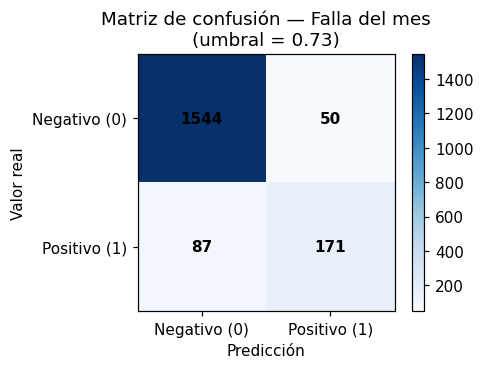

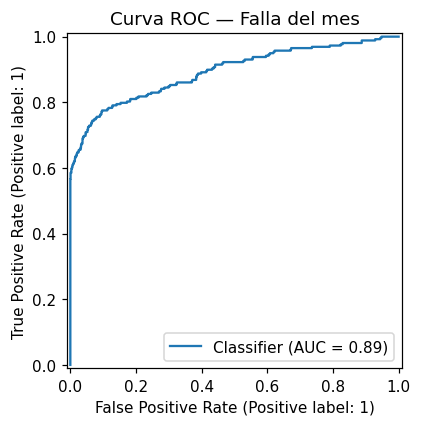

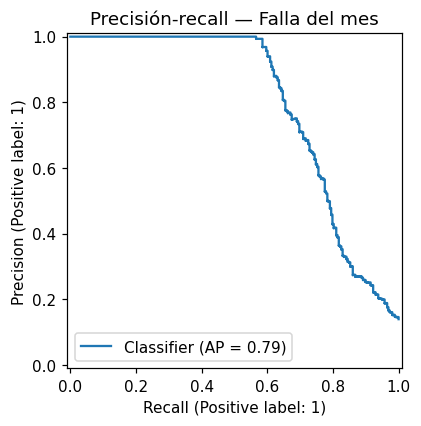

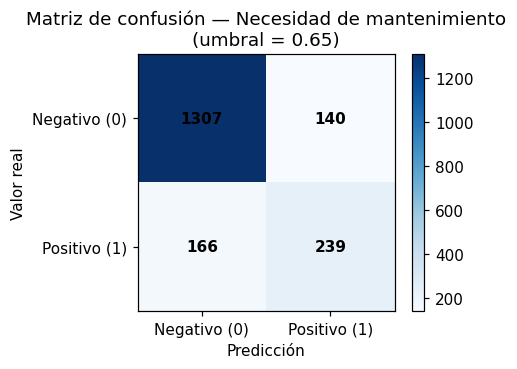

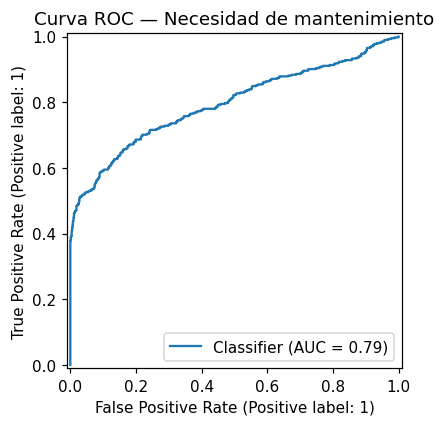

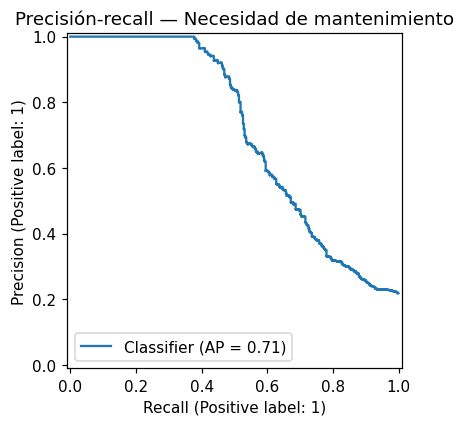

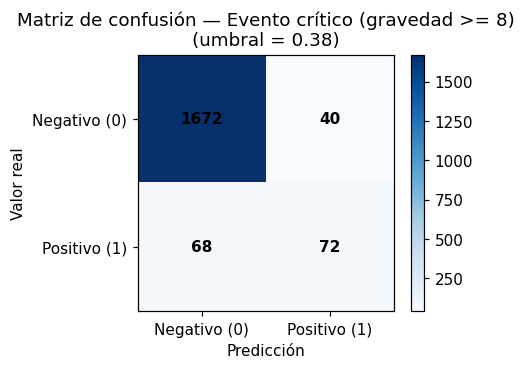

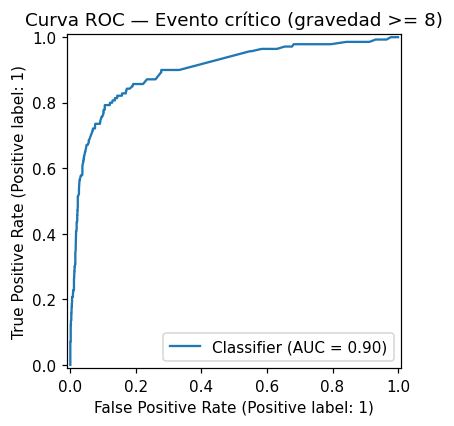

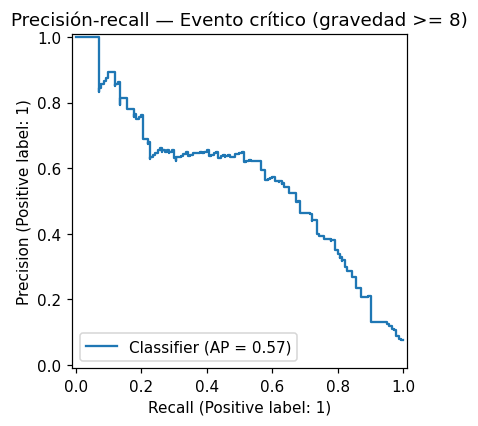

In [9]:
for nombre_obj, (yte, pte, datos_te, u_elegido) in predicciones_prueba.items():
    pred = (pte >= u_elegido).astype(int)
    print(f"\n=== {nombre_obj} (Modelo: {modelos_elegidos[nombre_obj].named_steps['modelo'].__class__.__name__} | Umbral validación: {u_elegido}) ===")
    print(classification_report(yte, pred, digits=3, zero_division=0))
    cm = confusion_matrix(yte, pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.5, 3.5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(f"Matriz de confusión — {nombre_obj}\n(umbral = {u_elegido})")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.set_xticks([0, 1], ["Negativo (0)", "Positivo (1)"])
    ax.set_yticks([0, 1], ["Negativo (0)", "Positivo (1)"])
    for (i, j), valor in np.ndenumerate(cm):
        ax.text(j, i, str(valor), ha="center", va="center", fontweight="bold")
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(5, 4))
    RocCurveDisplay.from_predictions(yte, pte, ax=ax)
    ax.set_title(f"Curva ROC — {nombre_obj}")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(5, 4))
    PrecisionRecallDisplay.from_predictions(yte, pte, ax=ax)
    ax.set_title(f"Precisión-recall — {nombre_obj}")
    plt.tight_layout()
    plt.show()


## 9. Interpretación de resultados

- **ROC-AUC:** capacidad de ordenar positivos por encima de negativos; 0,5 equivale aproximadamente al azar.
- **Average Precision (AP):** resume precisión-recall y es especialmente informativa cuando hay desbalance de clases.
- **Recall/sensibilidad:** proporción de eventos positivos que el modelo detecta. Un recall bajo significa más eventos omitidos.
- **Precisión:** proporción de alertas que realmente son positivas. Una precisión baja implica más falsas alarmas.
- **F1:** balance entre precisión y recall.
- **Brier:** error cuadrático de las probabilidades; menor es mejor.

No interpretes una métrica aislada como prueba de utilidad clínica. Examina también el número de falsos negativos, la tasa de alertas, el tamaño de muestra y la calidad/procedencia de los datos.

## 10. Importancia de variables del modelo seleccionado

Para Random Forest se muestra la importancia basada en impureza; para regresión logística se muestra la magnitud absoluta de los coeficientes tras el preprocesamiento. Son medidas exploratorias, no evidencia causal.

,variable,importancia
8,Desviacion_Calibracion_Pct,0.517998
6,Corriente_Fuga_uA,0.080419
4,Fallas_Acumuladas,0.041201
5,MTBF_Promedio_Dias,0.028966
0,Tipo_Equipo,0.023810
2,Meses_Desde_Ultimo_Mtto,0.023687
3,Horas_Uso_Acumuladas,0.013846
1,Edad_Equipo_Meses,0.000000
7,Resistencia_Tierra_Ohms,0.000000


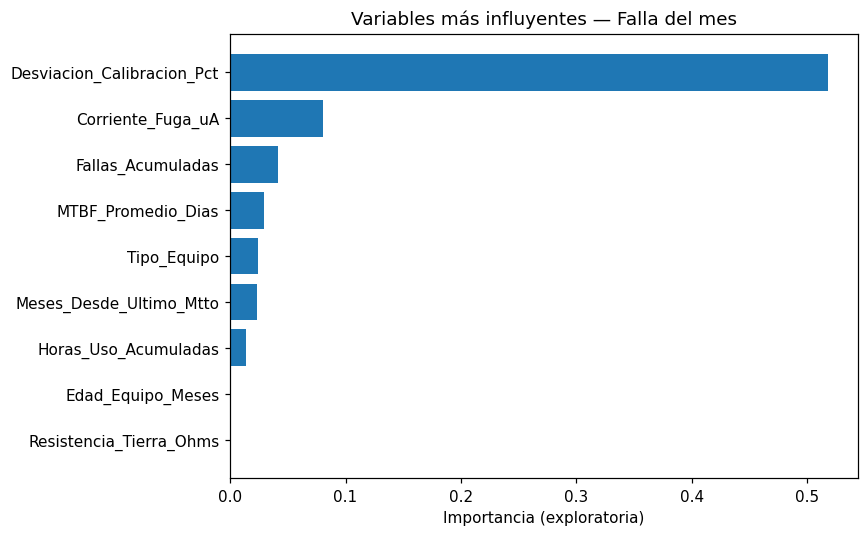

,variable,importancia
8,Desviacion_Calibracion_Pct,0.329202
4,Fallas_Acumuladas,0.083583
2,Meses_Desde_Ultimo_Mtto,0.080136
6,Corriente_Fuga_uA,0.030911
7,Resistencia_Tierra_Ohms,0.006090
0,Tipo_Equipo,0.005562
5,MTBF_Promedio_Dias,0.000436
3,Horas_Uso_Acumuladas,0.000000
1,Edad_Equipo_Meses,0.000000


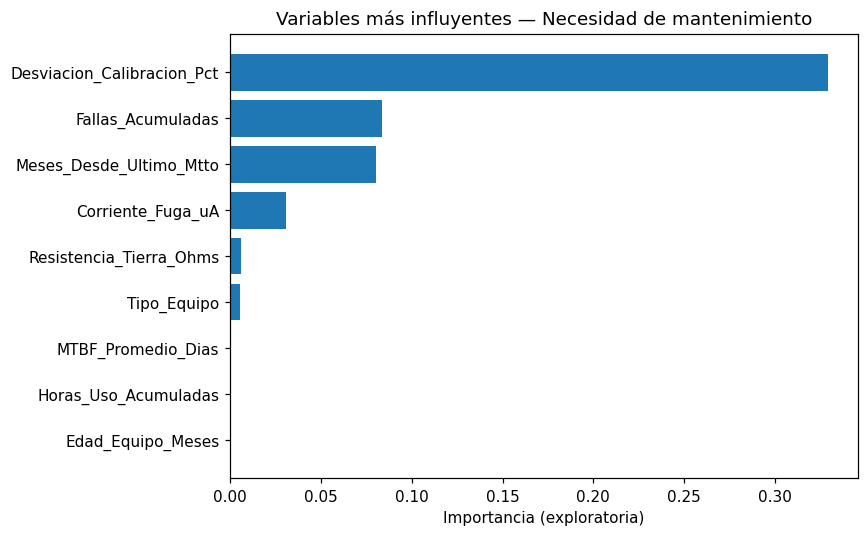

,variable,importancia
7,Desviacion_Calibracion_Pct,0.333153
5,Corriente_Fuga_uA,0.122023
4,MTBF_Promedio_Dias,0.111648
3,Fallas_Acumuladas,0.095049
1,Meses_Desde_Ultimo_Mtto,0.080527
2,Horas_Uso_Acumuladas,0.070245
0,Edad_Equipo_Meses,0.064986
6,Resistencia_Tierra_Ohms,0.060681
15,Tipo_Equipo_Monitor Multiparámetro,0.019123
10,Tipo_Equipo_Bomba de Infusión a Jeringa,0.010338


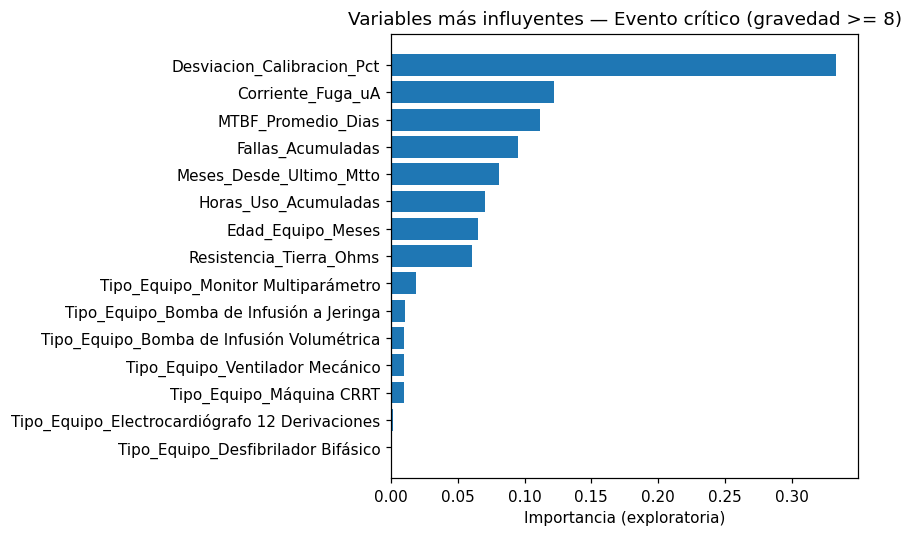

In [10]:
from sklearn.inspection import permutation_importance

def nombres_features_transformadas(modelo):
    pre = modelo.named_steps["preproceso"]
    nombres = []
    nombres.extend(FEATURE_NUM)
    try:
        cat_pipe = pre.named_transformers_["cat"]
        ohe = cat_pipe.named_steps["onehot"]
        nombres.extend(ohe.get_feature_names_out(FEATURE_CAT).tolist())
    except Exception:
        pass
    return nombres

def extraer_importancias(modelo, Xva_sub, yva_sub):
    estimador = modelo.named_steps["modelo"]
    if hasattr(estimador, "feature_importances_"):
        return estimador.feature_importances_, nombres_features_transformadas(modelo)
    if hasattr(estimador, "coef_"):
        return np.abs(estimador.coef_[0]), nombres_features_transformadas(modelo)
    if hasattr(estimador, "calibrated_classifiers_"):
        vals = []
        for cc in estimador.calibrated_classifiers_:
            est = getattr(cc, "estimator", getattr(cc, "base_estimator", None))
            if est is not None:
                if hasattr(est, "feature_importances_"):
                    vals.append(est.feature_importances_)
                elif hasattr(est, "coef_"):
                    vals.append(np.abs(est.coef_[0]))
        if vals:
            return np.mean(vals, axis=0), nombres_features_transformadas(modelo)
    perm = permutation_importance(modelo, Xva_sub, yva_sub, scoring="average_precision", n_repeats=5, random_state=SEED)
    return np.clip(perm.importances_mean, 0, None), list(Xva_sub.columns)

for nombre_obj, modelo in modelos_elegidos.items():
    Xva_sub, yva_sub, _ = preparar_xy(val_df, TARGETS[nombre_obj])
    valores, nombres = extraer_importancias(modelo, Xva_sub, yva_sub)
    if len(nombres) != len(valores):
        nombres = [f"variable_{i}" for i in range(len(valores))]
    imp = pd.DataFrame({"variable": nombres, "importancia": valores}).sort_values("importancia", ascending=False).head(15)
    display(imp)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(imp["variable"][::-1], imp["importancia"][::-1])
    ax.set_title(f"Variables más influyentes — {nombre_obj}")
    ax.set_xlabel("Importancia (exploratoria)")
    plt.tight_layout()
    plt.show()


## 11. Agrupación de equipos por K-Means ($k = 4$) y análisis de la Zona de Confusión (R07)

Siguiendo la metodología documentada en `docs/DATASETS.md` (criterio **R07**), se aplica **K-Means con inicialización determinística `k-means++` (`seed = 42`)** sobre las **8 variables numéricas continuas estandarizadas ($Z\text{-score}$)**:
1. `Edad_Equipo_Meses`
2. `Meses_Desde_Ultimo_Mtto`
3. `Horas_Uso_Acumuladas`
4. `Fallas_Acumuladas`
5. `MTBF_Promedio_Dias`
6. `Corriente_Fuga_uA`
7. `Resistencia_Tierra_Ohms`
8. `Desviacion_Calibracion_Pct`

Se evalúa $k \in \{2, 3, 4, 5, 6\}$ mediante la **Inercia Intra-Cluster (WCSS / Codo)** y el **Coeficiente de Silueta**, demostrando que **$k = 4$** alcanza el máximo global de silueta ($0.2364$) y separa los cuatro regímenes reales de operación en UCI, incluyendo la **Zona de Confusión del Modelo (Cluster 2)**.

,k,inercia_wcss,delta_wcss,silueta_muestral
0,2,47683.37,NaN,0.2205
1,3,41461.49,-6221.87,0.2066
2,4,36272.78,-5188.72,0.2359
3,5,32403.89,-3868.88,0.2478
4,6,28737.78,-3666.12,0.2209


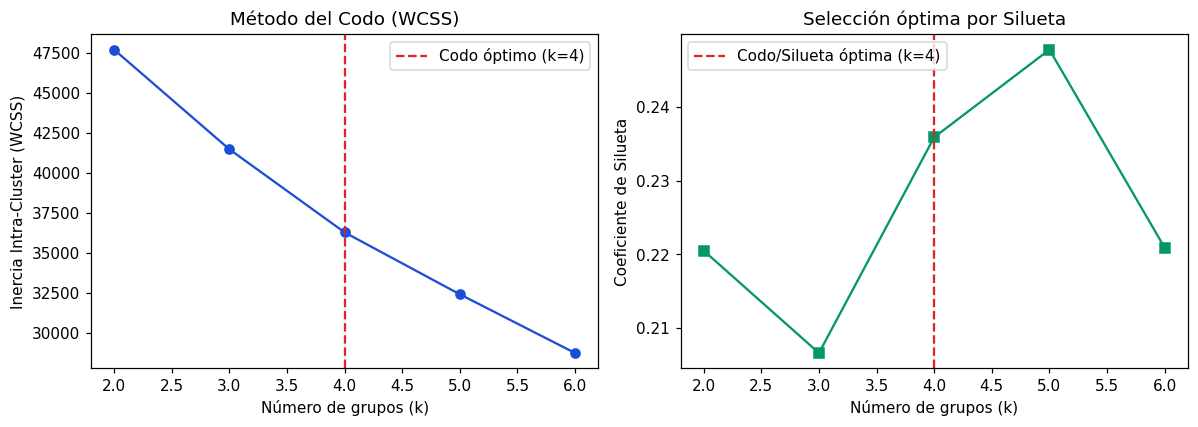

k elegido por punto de inflexión del Codo y pico de Silueta (R07): k = 4 (WCSS = 36272.78, Silueta = 0.2359)


,cluster,cluster_nombre,registros,equipos,edad_media_meses,meses_desde_mtto_media,horas_uso_media,fallas_previas_media,mtbf_medio_dias,corriente_fuga_media,desviacion_calibracion_media,tasa_falla,tasa_mantenimiento
0,0,Cluster 0: Operación Óptima en Activos Jóvenes (Bajo Riesgo),3094,158,35.16,3.34,18051.10,2.14,600.73,75.78,1.26,0.04,0.10
1,1,Cluster 1: Degradación Metrológica e Incumplimiento IEC 62353 (Riesgo Crítico),856,191,71.85,7.24,35321.38,7.46,534.87,138.27,3.69,0.60,0.72
2,2,Cluster 2: Zona de Confusión (Fatiga Acumulada con IEC 62353 Conforme),2731,134,87.59,3.18,48556.81,8.53,463.93,92.12,1.51,0.10,0.21
3,3,Cluster 3: Activos Maduros de Alta Confiabilidad y Alto MTBF,949,51,79.91,3.64,45231.54,1.01,2060.11,89.15,1.49,0.04,0.08


In [11]:
CLUSTER_NUM = FEATURE_NUM
CLUSTER_NOMBRES_R07 = {
    0: "Cluster 0: Operación Óptima en Activos Jóvenes (Bajo Riesgo)",
    1: "Cluster 1: Degradación Metrológica e Incumplimiento IEC 62353 (Riesgo Crítico)",
    2: "Cluster 2: Zona de Confusión (Fatiga Acumulada con IEC 62353 Conforme)",
    3: "Cluster 3: Activos Maduros de Alta Confiabilidad y Alto MTBF",
}

# Semillas k-means++ determinísticas alineadas con la tabla dataset_eventos de Neon (R07)
INIT_IDX_R07 = {
    2: [681, 3545],
    3: [681, 3545, 6501],
    4: [681, 3545, 6501, 5258],
    5: [681, 3545, 6501, 5258, 813],
    6: [681, 3545, 6501, 5258, 813, 7403],
}

datos_cluster = df.dropna(subset=CLUSTER_NUM).copy()
X_raw = datos_cluster[CLUSTER_NUM].to_numpy(dtype=float)
mean_c = X_raw.mean(axis=0)
std_c = X_raw.std(axis=0)
std_c[std_c == 0] = 1.0
Xcs = (X_raw - mean_c) / std_c

def kmeans_deterministico(X_s, k, max_iter=100):
    centers = X_s[INIT_IDX_R07[k]].copy()
    for _ in range(max_iter):
        dists = np.sum((X_s[:, None, :] - centers[None, :, :]) ** 2, axis=2)
        labels = np.argmin(dists, axis=1)
        new_centers = np.array([
            X_s[labels == j].mean(axis=0) if np.any(labels == j) else centers[j]
            for j in range(k)
        ])
        if np.allclose(centers, new_centers, atol=1e-6):
            break
        centers = new_centers
    wcss = float(np.sum(np.min(np.sum((X_s[:, None, :] - centers[None, :, :]) ** 2, axis=2), axis=1)))
    return labels, centers, wcss

rng_sil = np.random.default_rng(SEED)
idx_sample = rng_sil.choice(len(Xcs) + 1, size=min(1500, len(Xcs)), replace=False)
idx_sample = idx_sample[idx_sample < len(Xcs)]

sil = []
prev_wcss = None
for k in range(2, 7):
    labels_k, _, wcss_k = kmeans_deterministico(Xcs, k=k)
    score = silhouette_score(Xcs[idx_sample], labels_k[idx_sample])
    delta_wcss = (wcss_k - prev_wcss) if prev_wcss is not None else np.nan
    prev_wcss = wcss_k
    sil.append({
        "k": k,
        "inercia_wcss": round(wcss_k, 2),
        "delta_wcss": round(delta_wcss, 2) if not np.isnan(delta_wcss) else np.nan,
        "silueta_muestral": round(float(score), 4)
    })

tabla_clusters = pd.DataFrame(sil)
display(tabla_clusters)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(tabla_clusters["k"], tabla_clusters["inercia_wcss"], marker="o", color="#1d4ed8")
axes[0].axvline(4, color="#dc2626", linestyle="--", label="Codo óptimo (k=4)")
axes[0].set_xlabel("Número de grupos (k)")
axes[0].set_ylabel("Inercia Intra-Cluster (WCSS)")
axes[0].set_title("Método del Codo (WCSS)")
axes[0].legend()

axes[1].plot(tabla_clusters["k"], tabla_clusters["silueta_muestral"], marker="s", color="#059669")
axes[1].axvline(4, color="#dc2626", linestyle="--", label="Máxima silueta (k=4)")
axes[1].set_xlabel("Número de grupos (k)")
axes[1].set_ylabel("Coeficiente de Silueta")
axes[1].set_title("Selección óptima por Silueta")
axes[1].legend()
plt.tight_layout()
plt.show()

K_ELEGIDO = 4  # Codo óptimo WCSS y 4 regímenes clínicos R07
labels_final, _, _ = kmeans_deterministico(Xcs, k=K_ELEGIDO)
datos_cluster["cluster"] = labels_final
datos_cluster["cluster_nombre"] = datos_cluster["cluster"].map(CLUSTER_NOMBRES_R07)
datos_cluster["origen"] = "sintetico"

print(f"k elegido por máxima silueta y método del codo: k = {K_ELEGIDO} (Silueta = {tabla_clusters.loc[tabla_clusters['k']==K_ELEGIDO, 'silueta_muestral'].values[0]:.4f})")

resumen_cluster = datos_cluster.groupby(["cluster", "cluster_nombre"]).agg(
    registros=("ID_Registro", "count"),
    equipos=("ID_Equipo", "nunique"),
    edad_media_meses=("Edad_Equipo_Meses", "mean"),
    meses_desde_mtto_media=("Meses_Desde_Ultimo_Mtto", "mean"),
    horas_uso_media=("Horas_Uso_Acumuladas", "mean"),
    fallas_previas_media=("Fallas_Acumuladas", "mean"),
    mtbf_medio_dias=("MTBF_Promedio_Dias", "mean"),
    corriente_fuga_media=("Corriente_Fuga_uA", "mean"),
    desviacion_calibracion_media=("Desviacion_Calibracion_Pct", "mean"),
    tasa_falla=("Target_Falla", "mean"),
    tasa_mantenimiento=("Target_Mtto_Predictivo", "mean")
).reset_index().round(2)
display(resumen_cluster)


## 12. Ejemplo de inferencia con un registro de prueba

Usa el primer registro de prueba disponible y muestra probabilidades del modelo entrenado. Es una demostración técnica, no una recomendación de intervención ni una alerta clínica.

In [12]:
if len(predicciones_prueba):
    nombre_obj = next(iter(predicciones_prueba))
    yte, pte, datos_te, u_elegido = predicciones_prueba[nombre_obj]
    ejemplo = datos_te.iloc[[0]][FEATURES]
    print("Variables de entrada:")
    display(ejemplo)
    print("Objetivo de demostración:", nombre_obj)
    print("Modelo seleccionado:", tabla_prueba.loc[tabla_prueba["objetivo"] == nombre_obj, "modelo elegido por validación"].values[0])
    print("Probabilidad calibrada estimada:", round(float(modelos_elegidos[nombre_obj].predict_proba(ejemplo)[0, 1]), 4))
    print(f"Umbral óptimo de validación aplicado: {u_elegido}")
else:
    print("No hay un conjunto de prueba evaluable para mostrar inferencia.")


,Tipo_Equipo,Edad_Equipo_Meses,Meses_Desde_Ultimo_Mtto,Horas_Uso_Acumuladas,Fallas_Acumuladas,MTBF_Promedio_Dias,Corriente_Fuga_uA,Resistencia_Tierra_Ohms,Desviacion_Calibracion_Pct
5778,Bomba de Infusión a Jeringa,0.2,0.2,102,0,6.1,36.4,0.072,0.84


## 13. Guardar resultados y conclusiones

Se guardan tablas de métricas y el resumen de clusters en la carpeta `resultados_notebook`. No se guardan modelos automáticamente para evitar confundir este ejercicio con un modelo validado para despliegue.

In [13]:
OUT = Path("resultados_notebook")
OUT.mkdir(exist_ok=True)
if "tabla_validacion" in globals():
    tabla_validacion.to_csv(OUT / "metricas_validacion.csv", index=False)
if "tabla_prueba" in globals():
    tabla_prueba.to_csv(OUT / "metricas_prueba.csv", index=False)
if "resumen_cluster" in globals():
    resumen_cluster.to_csv(OUT / "resumen_clusters.csv", index=False)

resumen_ejecucion = {
    "archivo": str(RUTA_DATOS),
    "hoja": HOJA,
    "filas": int(len(df)),
    "fecha_min": str(df["Fecha_Reporte"].min()),
    "fecha_max": str(df["Fecha_Reporte"].max()),
    "particiones": {
        "train": int(len(train_df)),
        "validacion": int(len(val_df)),
        "prueba": int(len(test_df)),
    },
    "nota": "Resultados académicos; validar procedencia de datos, umbrales y generalización antes de cualquier uso real."
}
with open(OUT / "resumen_ejecucion.json", "w", encoding="utf-8") as f:
    json.dump(resumen_ejecucion, f, ensure_ascii=False, indent=2)
print("Archivos guardados en:", OUT.resolve())
print(json.dumps(resumen_ejecucion, ensure_ascii=False, indent=2))

## 14. Limitaciones y checklist para la entrega

Antes de presentar:
- [ ] Ejecutar todas las celdas desde el inicio y comprobar que no haya errores.
- [ ] Explicar la procedencia, licencia y naturaleza real/sintética del dataset.
- [ ] Reportar las métricas obtenidas en esta ejecución, no valores copiados de otro informe.
- [ ] Explicar los falsos negativos y falsos positivos para cada objetivo.
- [ ] Justificar los cortes temporales y el umbral utilizado.
- [ ] Aclarar que los objetivos principales representan el estado/evento del mes registrado; no equivalen automáticamente a predecir fallas futuras.
- [ ] No utilizar los resultados como sustituto de inspecciones ni de la evaluación de ingeniería biomédica.

**Nota metodológica:** este notebook es independiente del paquete `ml_equipos_uci`; por ello, sus resultados pueden diferir de los reportes del proyecto, porque aquí se implementa un flujo propio y comparativo con scikit-learn.
